# setup + imports

In [1]:
%pip install transformers

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

/Users/ecaterina/practice/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans


In [4]:
test_data = pd.read_csv("test_data.csv")
model_path = "BAAI/bge-small-en-v1.5"    
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModel.from_pretrained(model_path)
model.eval()

W1022 19:21:54.155000 26202 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|████████████████████| 199/199 [00:00<00:00, 12215.41it/s]


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 384, padding_idx=0)
    (position_embeddings): Embedding(512, 384)
    (token_type_embeddings): Embedding(2, 384)
    (LayerNorm): LayerNorm((384,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=384, out_features=384, bias=True)
            (key): Linear(in_features=384, out_features=384, bias=True)
            (value): Linear(in_features=384, out_features=384, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=384, out_features=384, bias=True)
            (LayerNorm): LayerNorm((384,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [5]:
test_data.shape

(7000, 2)

In [6]:
texts = list(test_data['text'].astype(str))
embs = []
for t in texts:
    enc = tokenizer(t, truncation=True, max_length=512, return_tensors="pt")
    with torch.no_grad():
        out = model(**enc)
    v = out[0][0, 0].numpy()            
    v = v / np.sqrt(np.sum(v ** 2))     
    embs.append(v)
embs = np.array(embs)                         


In [7]:
print(embs.shape)

(7000, 384)


In [8]:
print(len(test_data))
for t in test_data['text'].sample(10, random_state=0):
    print('-', t[:150])

7000
- 5  #39;inside #39; directors quit Marsh board Embattled insurance broker Marsh  amp; McLennan Cos. said yesterday that five members of its board of di
- Search Engine Forums Spotlight Links to this week's topics from search engine forums across the web: Click-Fraud Said to be 50 of Clicks - PPC  #91;Pa
- Nokia, Vodafone push for mobile Java standards The world's largest mobile phone manufacturer and Europe's largest wireless operator have launched an i
- Deluxe Handhelds Try Hard to Justify the Price (washingtonpost.com) washingtonpost.com - When  #36;100 buys a pocket-sized gadget that can store decad
- Shopping Cart Search Engine Optimization Shopping Cart Search Engine Optimization\\I had a few interesting conversations about shopping carts last wee
- Coles Myer rings up record profit Australia #39;s biggest retailer Coles Myer has posted a record net profit of Aust. \$576.5 million (\$403 million) 
- Thus shares plunge after warning Shares in telecoms group Thus drop nearly 

# model

In [9]:
for k in range(2, 13):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(embs)
    print(k, round(silhouette_score(embs, labels), 3))

2 0.057
3 0.046
4 0.049
5 0.048
6 0.043
7 0.041
8 0.042
9 0.033
10 0.038
11 0.03
12 0.03


In [14]:
K = 5
labels = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(embs)

for c in range(K):
    print('=== cluster', c, 'size', np.sum(labels == c))
    for t in test_data['text'][labels == c].head(4):
        print('   ', t[:120])

=== cluster 0 size 1334
    School #39;s out to shun IE Citing security risks, a state university is urging students to drop Internet Explorer in fa
    IU Researchers Helping to Study Video Game Violence Link (Indianapolis) - Indiana University researchers are trying to f
    Da Vinci Team Delays Launch A Canadian team vying for the \$10 million X Prize is scrounging for parts, while the heavy 
    Toshiba, NEC plan HD DVD notebooks in 2005 TOKYO - Toshiba Corp. and NEC Corp. said they are backing the HD DVD format o
=== cluster 1 size 1063
    DESPERATE EXECUTIVES The ABC television network is rightly being pilloried from all concerned - including FCC Chairman M
    Clemens in Game 7 -- perfect ST. LOUIS -- This was the kind of deflating loss that would send some teams -- the Cubs com
    England, Italy, France Win England lifts the pressure off Coach Sven-Goran Eriksson with a 2-1 win at Poland in a World 
    Els fires 64 to surge into lead at WGC-American Express Ernie Els finally

# viz

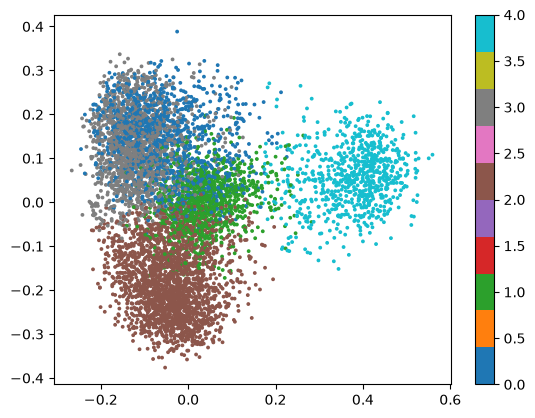

In [15]:
P = PCA(n_components=2).fit_transform(embs)
plt.scatter(P[:, 0], P[:, 1], c=labels, s=3, cmap='tab10')
plt.colorbar()
plt.show()


# submission

In [16]:
NOISE = [4]                                         
news_number = {}
next_id = 1
for c in range(K):
    if c not in NOISE:
        news_number[c] = next_id       
        next_id += 1  

ans1 = []
ans2 = []
for c in labels:
    if c in NOISE:
        ans1.append(1)
        ans2.append(-1)
    else:
        ans1.append(0)
        ans2.append(news_number[c])

ids = test_data['datapointID']
sub1 = pd.DataFrame({'subtaskID': 1, 'datapointID': ids, 'answer': ans1})
sub2 = pd.DataFrame({'subtaskID': 2, 'datapointID': ids, 'answer': ans2})
pd.concat([sub1, sub2], ignore_index=True).to_csv("output.csv", index=False)